In [1]:
import scipy.stats as stats
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv(r"C:\Users\Nishant\OneDrive\Documents\IndusSync\Data\Thales_Group_Manufacturing.csv")

In [4]:
analysis_data = df[[
    "Network_Latency_ms",
    "Packet_Loss_%",
    "Error_Rate_%",
    "Production_Speed_units_per_hr",
    "Quality_Control_Defect_Rate_%",
    "Power_Consumption_kW",
    "Temperature_C",
    "Vibration_Hz"
]]

In [5]:
print(analysis_data.describe())

       Network_Latency_ms  Packet_Loss_%   Error_Rate_%  \
count        100000.00000  100000.000000  100000.000000   
mean             25.55562       2.493418       7.504101   
std              14.12076       1.443273       4.335895   
min               1.00000       0.000000       0.000000   
25%              13.35500       1.245000       3.750000   
50%              25.53600       2.488000       7.504000   
75%              37.79625       3.741000      11.273000   
max              50.00000       5.000000      15.000000   

       Production_Speed_units_per_hr  Quality_Control_Defect_Rate_%  \
count                  100000.000000                  100000.000000   
mean                      275.916324                       5.008806   
std                       130.096892                       2.883666   
min                        50.000000                       0.000000   
25%                       162.873750                       2.521750   
50%                       276.649000      

In [6]:
correlation = analysis_data.corr()

print(correlation)

                               Network_Latency_ms  Packet_Loss_%  \
Network_Latency_ms                       1.000000      -0.006886   
Packet_Loss_%                           -0.006886       1.000000   
Error_Rate_%                             0.000098      -0.002407   
Production_Speed_units_per_hr           -0.001050      -0.007119   
Quality_Control_Defect_Rate_%           -0.004356      -0.004897   
Power_Consumption_kW                    -0.003244      -0.001198   
Temperature_C                           -0.002467       0.002861   
Vibration_Hz                             0.007546       0.000396   

                               Error_Rate_%  Production_Speed_units_per_hr  \
Network_Latency_ms                 0.000098                      -0.001050   
Packet_Loss_%                     -0.002407                      -0.007119   
Error_Rate_%                       1.000000                       0.006070   
Production_Speed_units_per_hr      0.006070                       1.000000 

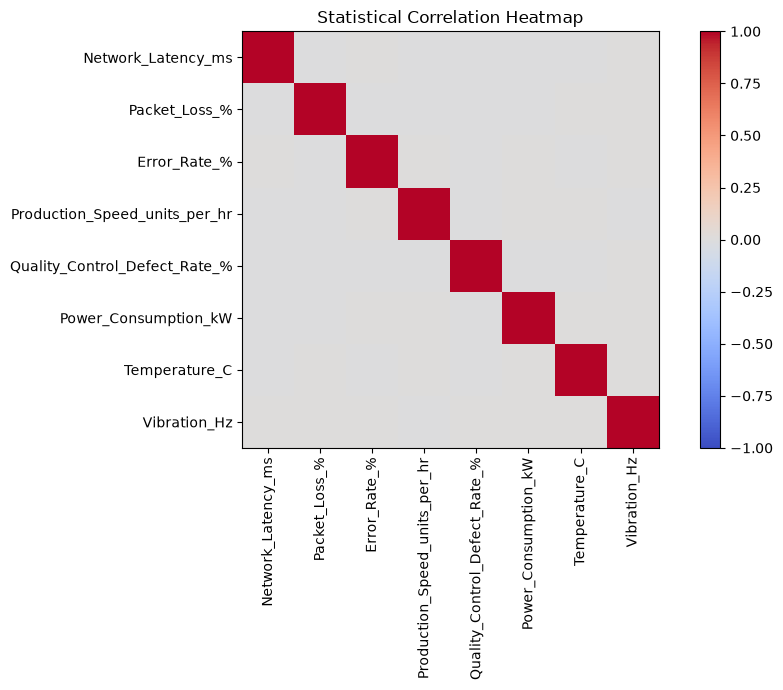

In [7]:
plt.figure(figsize=(10, 7))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(range(len(correlation.columns)), correlation.columns, rotation=90)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Statistical Correlation Heatmap")

plt.tight_layout()
plt.show()

In [9]:
df["Latency_Category"] = pd.cut(
    df["Network_Latency_ms"],
    bins=[-float("inf"), 30, 60, float("inf")],
    labels=["Low", "Medium", "High"]
)

print("Latency categories created successfully!")

Latency categories created successfully!


In [10]:
df["Packet_Loss_Category"] = pd.cut(
    df["Packet_Loss_%"],
    bins=[-float("inf"), 1, 3, float("inf")],
    labels=["Low", "Medium", "High"]
)

print("Packet loss categories created successfully!")

Packet loss categories created successfully!


In [11]:
low_latency = df[df["Latency_Category"] == "Low"]["Production_Speed_units_per_hr"]

high_latency = df[df["Latency_Category"] == "High"]["Production_Speed_units_per_hr"]

t_stat, p_value = stats.ttest_ind(
    low_latency,
    high_latency,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: nan
P-value: nan


C:\Users\Nishant\AppData\Local\Temp\ipykernel_20356\2097653260.py:5: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat, p_value = stats.ttest_ind(


In [12]:
if p_value < 0.05:
    print("Result: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("Result: No statistically significant difference.")
    print("Fail to reject the null hypothesis.")

Result: No statistically significant difference.
Fail to reject the null hypothesis.


In [13]:
low_latency_defects = df[df["Latency_Category"] == "Low"]["Quality_Control_Defect_Rate_%"]

high_latency_defects = df[df["Latency_Category"] == "High"]["Quality_Control_Defect_Rate_%"]

t_stat_defect, p_value_defect = stats.ttest_ind(
    low_latency_defects,
    high_latency_defects,
    equal_var=False
)

print("T-statistic:", t_stat_defect)
print("P-value:", p_value_defect)

T-statistic: nan
P-value: nan


C:\Users\Nishant\AppData\Local\Temp\ipykernel_20356\3422547471.py:5: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  t_stat_defect, p_value_defect = stats.ttest_ind(


In [14]:
if p_value_defect < 0.05:
    print("Result: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("Result: No statistically significant difference.")
    print("Fail to reject the null hypothesis.")

Result: No statistically significant difference.
Fail to reject the null hypothesis.


In [15]:
low_packet = df[df["Packet_Loss_Category"] == "Low"]["Production_Speed_units_per_hr"]

high_packet = df[df["Packet_Loss_Category"] == "High"]["Production_Speed_units_per_hr"]

t_stat_packet, p_value_packet = stats.ttest_ind(
    low_packet,
    high_packet,
    equal_var=False
)

print("T-statistic:", t_stat_packet)
print("P-value:", p_value_packet)

T-statistic: 2.264065318470525
P-value: 0.02357536304021976


In [16]:
if p_value_packet < 0.05:
    print("Result: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("Result: No statistically significant difference.")
    print("Fail to reject the null hypothesis.")

Result: Statistically significant difference.
Reject the null hypothesis.


In [17]:
low_packet_defects = df[df["Packet_Loss_Category"] == "Low"]["Quality_Control_Defect_Rate_%"]

high_packet_defects = df[df["Packet_Loss_Category"] == "High"]["Quality_Control_Defect_Rate_%"]

t_stat_packet_defect, p_value_packet_defect = stats.ttest_ind(
    low_packet_defects,
    high_packet_defects,
    equal_var=False
)

print("T-statistic:", t_stat_packet_defect)
print("P-value:", p_value_packet_defect)

T-statistic: 2.125841407649585
P-value: 0.03352252551841189


In [18]:
if p_value_packet_defect < 0.05:
    print("Result: Statistically significant difference.")
    print("Reject the null hypothesis.")
else:
    print("Result: No statistically significant difference.")
    print("Fail to reject the null hypothesis.")

Result: Statistically significant difference.
Reject the null hypothesis.


In [19]:
results = {
    "Test": [
        "Latency vs Production Speed",
        "Latency vs Defect Rate",
        "Packet Loss vs Production Speed",
        "Packet Loss vs Defect Rate"
    ],
    "T_Statistic": [
        t_stat,
        t_stat_defect,
        t_stat_packet,
        t_stat_packet_defect
    ],
    "P_Value": [
        p_value,
        p_value_defect,
        p_value_packet,
        p_value_packet_defect
    ]
}

results_df = pd.DataFrame(results)

print(results_df)

                              Test  T_Statistic   P_Value
0      Latency vs Production Speed          NaN       NaN
1           Latency vs Defect Rate          NaN       NaN
2  Packet Loss vs Production Speed     2.264065  0.023575
3       Packet Loss vs Defect Rate     2.125841  0.033523


In [20]:
results_df["Result"] = results_df["P_Value"].apply(
    lambda x: "Significant" if x < 0.05 else "Not Significant"
)

print(results_df)

                              Test  T_Statistic   P_Value           Result
0      Latency vs Production Speed          NaN       NaN  Not Significant
1           Latency vs Defect Rate          NaN       NaN  Not Significant
2  Packet Loss vs Production Speed     2.264065  0.023575      Significant
3       Packet Loss vs Defect Rate     2.125841  0.033523      Significant


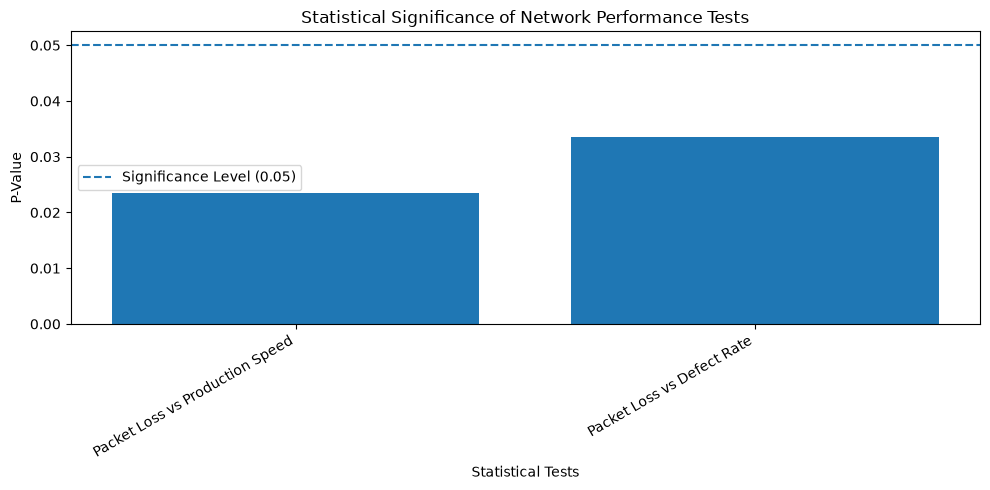

In [21]:
plt.figure(figsize=(10, 5))

plt.bar(results_df["Test"], results_df["P_Value"])

plt.axhline(y=0.05, linestyle="--", label="Significance Level (0.05)")

plt.xlabel("Statistical Tests")
plt.ylabel("P-Value")
plt.title("Statistical Significance of Network Performance Tests")

plt.xticks(rotation=30, ha="right")
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
results_df.to_csv("statistical_analysis_results.csv", index=False)

print("Statistical results saved successfully!")

Statistical results saved successfully!


In [23]:
r, p = stats.pearsonr(
    df["Network_Latency_ms"],
    df["Production_Speed_units_per_hr"]
)

print("Correlation:", r)
print("P-value:", p)

Correlation: -0.0010496586330944698
P-value: 0.7399442711524317


In [24]:
r_packet, p_packet = stats.pearsonr(
    df["Packet_Loss_%"],
    df["Production_Speed_units_per_hr"]
)

print("Correlation:", r_packet)
print("P-value:", p_packet)

Correlation: -0.007118679907857106
P-value: 0.02437764517591259


In [25]:
r_defect, p_defect = stats.pearsonr(
    df["Network_Latency_ms"],
    df["Quality_Control_Defect_Rate_%"]
)

print("Correlation:", r_defect)
print("P-value:", p_defect)

Correlation: -0.004356115380632588
P-value: 0.16835340452138095


In [26]:
r_packet_defect, p_packet_defect = stats.pearsonr(
    df["Packet_Loss_%"],
    df["Quality_Control_Defect_Rate_%"]
)

print("Correlation:", r_packet_defect)
print("P-value:", p_packet_defect)

Correlation: -0.00489688118166696
P-value: 0.12149721690377611


In [27]:
correlation_results = pd.DataFrame({
    "Relationship": [
        "Latency vs Production Speed",
        "Packet Loss vs Production Speed",
        "Latency vs Defect Rate",
        "Packet Loss vs Defect Rate"
    ],
    "Correlation": [
        r,
        r_packet,
        r_defect,
        r_packet_defect
    ],
    "P_Value": [
        p,
        p_packet,
        p_defect,
        p_packet_defect
    ]
})

print(correlation_results)

                      Relationship  Correlation   P_Value
0      Latency vs Production Speed    -0.001050  0.739944
1  Packet Loss vs Production Speed    -0.007119  0.024378
2           Latency vs Defect Rate    -0.004356  0.168353
3       Packet Loss vs Defect Rate    -0.004897  0.121497


In [28]:
def correlation_strength(value):
    value = abs(value)

    if value < 0.20:
        return "Very Weak"
    elif value < 0.40:
        return "Weak"
    elif value < 0.60:
        return "Moderate"
    elif value < 0.80:
        return "Strong"
    else:
        return "Very Strong"


correlation_results["Strength"] = correlation_results["Correlation"].apply(correlation_strength)

print(correlation_results)

                      Relationship  Correlation   P_Value   Strength
0      Latency vs Production Speed    -0.001050  0.739944  Very Weak
1  Packet Loss vs Production Speed    -0.007119  0.024378  Very Weak
2           Latency vs Defect Rate    -0.004356  0.168353  Very Weak
3       Packet Loss vs Defect Rate    -0.004897  0.121497  Very Weak


In [29]:
def correlation_direction(value):
    if value > 0:
        return "Positive"
    elif value < 0:
        return "Negative"
    else:
        return "No Linear Relationship"


correlation_results["Direction"] = correlation_results["Correlation"].apply(correlation_direction)

print(correlation_results)

                      Relationship  Correlation   P_Value   Strength Direction
0      Latency vs Production Speed    -0.001050  0.739944  Very Weak  Negative
1  Packet Loss vs Production Speed    -0.007119  0.024378  Very Weak  Negative
2           Latency vs Defect Rate    -0.004356  0.168353  Very Weak  Negative
3       Packet Loss vs Defect Rate    -0.004897  0.121497  Very Weak  Negative


In [30]:
correlation_results["Significance"] = correlation_results["P_Value"].apply(
    lambda value: "Significant" if value < 0.05 else "Not Significant"
)

print(correlation_results)

                      Relationship  Correlation   P_Value   Strength  \
0      Latency vs Production Speed    -0.001050  0.739944  Very Weak   
1  Packet Loss vs Production Speed    -0.007119  0.024378  Very Weak   
2           Latency vs Defect Rate    -0.004356  0.168353  Very Weak   
3       Packet Loss vs Defect Rate    -0.004897  0.121497  Very Weak   

  Direction     Significance  
0  Negative  Not Significant  
1  Negative      Significant  
2  Negative  Not Significant  
3  Negative  Not Significant  


In [31]:
print("FINAL CORRELATION ANALYSIS RESULTS")

print(correlation_results.round(4))

FINAL CORRELATION ANALYSIS RESULTS
                      Relationship  Correlation  P_Value   Strength Direction  \
0      Latency vs Production Speed      -0.0010   0.7399  Very Weak  Negative   
1  Packet Loss vs Production Speed      -0.0071   0.0244  Very Weak  Negative   
2           Latency vs Defect Rate      -0.0044   0.1684  Very Weak  Negative   
3       Packet Loss vs Defect Rate      -0.0049   0.1215  Very Weak  Negative   

      Significance  
0  Not Significant  
1      Significant  
2  Not Significant  
3  Not Significant  


In [32]:
correlation_results.to_csv(
    "final_correlation_analysis.csv",
    index=False
)

print("Correlation results saved successfully!")

Correlation results saved successfully!


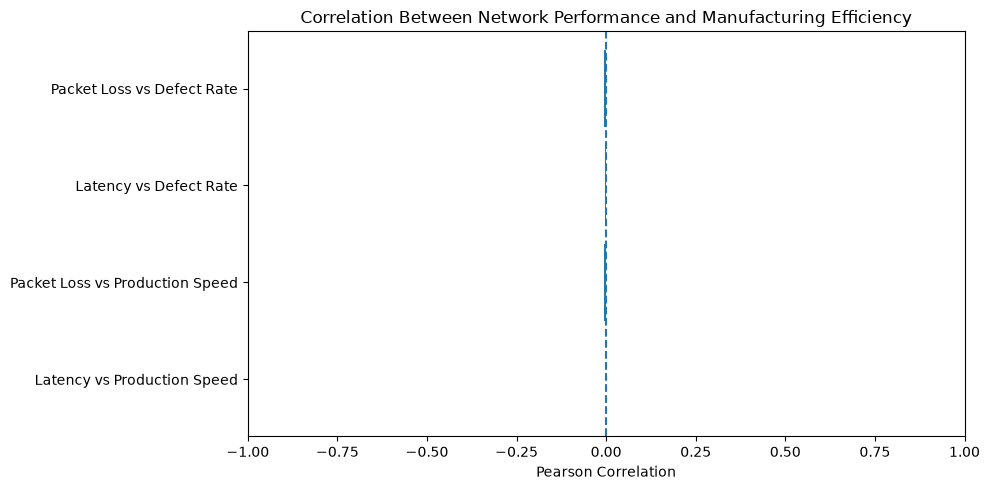

In [33]:
plt.figure(figsize=(10, 5))

plt.barh(
    correlation_results["Relationship"],
    correlation_results["Correlation"]
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Pearson Correlation")
plt.title("Correlation Between Network Performance and Manufacturing Efficiency")

plt.xlim(-1, 1)
plt.tight_layout()
plt.show()